In [ ]:
# Cell 1 — Install/import the libraries
%pip -q install --upgrade xgboost scikit-learn pandas numpy matplotlib


In [1]:
# Cell 2 — Imports and reproducible settings
import os
import gc
import json
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    precision_recall_curve,
)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
TARGET_RECALL = 0.95
N_ESTIMATORS = 300

DATA_PATH = Path("/content/data.csv")
OUTPUT_DIR = Path("/content/fraud_deployment_v2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("XGBoost version:", xgb.__version__)
print("Output directory:", OUTPUT_DIR)
print("Target validation recall:", TARGET_RECALL)


XGBoost version: 3.4.1
Output directory: /content/fraud_deployment_v2
Target validation recall: 0.95


In [2]:
# Cell 3 — Locate/load the PaySim CSV
# Expected file name: data.csv. If it is not already in /content, upload the CSV.
if not DATA_PATH.exists():
    try:
        from google.colab import files
        print("Upload your PaySim data.csv file.")
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("No CSV file was uploaded.")
        selected_name = "data.csv" if "data.csv" in csv_names else csv_names[0]
        DATA_PATH = Path("/content") / selected_name
    except ImportError as exc:
        raise FileNotFoundError(
            f"Dataset not found at {DATA_PATH}. Set DATA_PATH to your CSV location."
        ) from exc

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find dataset: {DATA_PATH}")

REQUIRED_COLUMNS = [
    "step", "type", "amount", "oldbalanceOrg", "oldbalanceDest", "isFraud"
]

df = pd.read_csv(DATA_PATH, usecols=REQUIRED_COLUMNS, low_memory=False)

print("Dataset path:", DATA_PATH)
print("Loaded shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Dataset path: /content/data.csv
Loaded shape: (6362620, 6)
Columns: ['step', 'type', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'isFraud']


,step,type,amount,oldbalanceOrg,oldbalanceDest,isFraud
0,1,PAYMENT,9839.64,170136.0,0.0,0
1,1,PAYMENT,1864.28,21249.0,0.0,0
2,1,TRANSFER,181.00,181.0,0.0,1
3,1,CASH_OUT,181.00,181.0,21182.0,1
4,1,PAYMENT,11668.14,41554.0,0.0,0


In [3]:
# Cell 4 — Validate and clean only the fields required for prediction
# Keep the target strictly binary; do not silently turn unknown labels into non-fraud.
original_rows = len(df)

for col in ["step", "amount", "oldbalanceOrg", "oldbalanceDest", "isFraud"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["step", "type", "isFraud"]).copy()
df = df[df["isFraud"].isin([0, 1])].copy()
df["isFraud"] = df["isFraud"].astype("int8")
df["step"] = df["step"].astype("int32")
df["type"] = df["type"].astype(str)

TRANSACTION_TYPES = ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"]
observed_types = sorted(df["type"].dropna().unique().tolist())
unexpected_types = sorted(set(observed_types) - set(TRANSACTION_TYPES))
if unexpected_types:
    raise ValueError(
        f"Unexpected transaction types {unexpected_types}. "
        "Inspect the dataset before continuing; do not silently discard them."
    )

print(f"Rows originally loaded: {original_rows:,}")
print(f"Rows after target/step/type validation: {len(df):,}")
print(f"Rows excluded: {original_rows - len(df):,}")
print("\nTarget counts:")
print(df["isFraud"].value_counts().sort_index().rename(index={0: "Non-fraud", 1: "Fraud"}))
print("\nFraud prevalence: {:.6%}".format(df["isFraud"].mean()))
print("Unique time steps:", df["step"].nunique())
print("Step range:", int(df["step"].min()), "to", int(df["step"].max()))


Rows originally loaded: 6,362,620
Rows after target/step/type validation: 6,362,620
Rows excluded: 0

Target counts:
isFraud
Non-fraud    6354407
Fraud           8213
Name: count, dtype: int64

Fraud prevalence: 0.129082%
Unique time steps: 743
Step range: 1 to 743


In [4]:
# Cell 5 — Build leakage-aware features and chronological train/validation/test sets
# Available-before-transaction features:
#   step, amount, oldbalanceOrg, oldbalanceDest, transaction type
# Excluded:
#   newbalanceOrig/newbalanceDest (post-transaction outcomes),
#   nameOrig/nameDest (high-cardinality identifiers),
#   isFlaggedFraud (rule-generated flag, not a general predictive input).

NUMERIC_FEATURES = ["step", "amount", "oldbalanceOrg", "oldbalanceDest"]
TYPE_FEATURES = [f"type_{t}" for t in TRANSACTION_TYPES]
FEATURE_NAMES = NUMERIC_FEATURES + TYPE_FEATURES

steps = df["step"].to_numpy(copy=True)
y_all = df["isFraud"].to_numpy(dtype=np.int8, copy=True)

feature_source = df[NUMERIC_FEATURES + ["type"]].copy()
X_all = pd.get_dummies(
    feature_source,
    columns=["type"],
    prefix=["type"],
    dtype=np.uint8
)
X_all = X_all.reindex(columns=FEATURE_NAMES, fill_value=0)

# Convert numeric predictors to float32 to reduce memory; missing numeric values
# are imputed below using medians calculated from the training partition only.
for col in NUMERIC_FEATURES:
    X_all[col] = pd.to_numeric(X_all[col], errors="coerce").astype("float32")
X_all = X_all.astype("float32")

unique_steps = np.sort(np.unique(steps))
if len(unique_steps) < 10:
    raise ValueError("Too few unique time steps for a reliable chronological split.")

train_end_idx = int(len(unique_steps) * 0.70)
val_end_idx = int(len(unique_steps) * 0.85)
train_end_idx = min(max(train_end_idx, 1), len(unique_steps) - 2)
val_end_idx = min(max(val_end_idx, train_end_idx + 1), len(unique_steps) - 1)

train_end_step = int(unique_steps[train_end_idx])
val_end_step = int(unique_steps[val_end_idx])

train_mask = steps < train_end_step
val_mask = (steps >= train_end_step) & (steps < val_end_step)
test_mask = steps >= val_end_step

if not train_mask.any() or not val_mask.any() or not test_mask.any():
    raise ValueError("At least one chronological partition is empty. Check step values.")

# Fit preprocessing statistics on training data only.
training_medians = X_all.loc[train_mask].median().fillna(0.0)
X_all = X_all.fillna(training_medians).astype("float32")

X_train = X_all.loc[train_mask].copy()
X_val = X_all.loc[val_mask].copy()
X_test = X_all.loc[test_mask].copy()

y_train = y_all[train_mask]
y_val = y_all[val_mask]
y_test = y_all[test_mask]

split_summary = pd.DataFrame([
    {
        "partition": "Train",
        "rows": len(y_train),
        "fraud_cases": int(y_train.sum()),
        "fraud_rate": float(y_train.mean()),
        "min_step": int(steps[train_mask].min()),
        "max_step": int(steps[train_mask].max()),
    },
    {
        "partition": "Validation",
        "rows": len(y_val),
        "fraud_cases": int(y_val.sum()),
        "fraud_rate": float(y_val.mean()),
        "min_step": int(steps[val_mask].min()),
        "max_step": int(steps[val_mask].max()),
    },
    {
        "partition": "Test",
        "rows": len(y_test),
        "fraud_cases": int(y_test.sum()),
        "fraud_rate": float(y_test.mean()),
        "min_step": int(steps[test_mask].min()),
        "max_step": int(steps[test_mask].max()),
    },
])

print("Feature count:", len(FEATURE_NAMES))
print("Features:", FEATURE_NAMES)
print("Training cutoff step (exclusive):", train_end_step)
print("Validation cutoff step (exclusive):", val_end_step)
display(split_summary)

assert X_train.columns.tolist() == FEATURE_NAMES
assert X_val.columns.tolist() == FEATURE_NAMES
assert X_test.columns.tolist() == FEATURE_NAMES
assert steps[train_mask].max() < steps[val_mask].min()
assert steps[val_mask].max() < steps[test_mask].min()

# Release the full feature matrix and source DataFrame after partitions are created.
del X_all, feature_source, df
gc.collect()


Feature count: 9
Features: ['step', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']
Training cutoff step (exclusive): 521
Validation cutoff step (exclusive): 632


,partition,rows,fraud_cases,fraud_rate,min_step,max_step
0,Train,6082007,5781,0.000951,1,520
1,Validation,191147,1180,0.006173,521,631
2,Test,89466,1252,0.013994,632,743


0

In [5]:
# Cell 6 — Train XGBoost once, using the training partition only
n_positive = int(y_train.sum())
n_negative = int(len(y_train) - n_positive)
if n_positive == 0:
    raise ValueError("Training partition has no fraud cases; cannot train a fraud classifier.")

scale_pos_weight = n_negative / n_positive
print(f"Training rows: {len(y_train):,}")
print(f"Training fraud cases: {n_positive:,}")
print(f"Training non-fraud cases: {n_negative:,}")
print(f"scale_pos_weight: {scale_pos_weight:.4f}")

model = xgb.XGBClassifier(
    n_estimators=N_ESTIMATORS,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist",
    max_bin=256,
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=50,
)

print("\nTraining completed.")
print("Trees in fitted model:", model.get_booster().num_boosted_rounds())
print("Model feature count:", len(model.get_booster().feature_names or []))


Training rows: 6,082,007
Training fraud cases: 5,781
Training non-fraud cases: 6,076,226
scale_pos_weight: 1051.0683
[0]	validation_0-aucpr:0.62194
[50]	validation_0-aucpr:0.86379
[100]	validation_0-aucpr:0.88908
[150]	validation_0-aucpr:0.90452
[200]	validation_0-aucpr:0.91515
[250]	validation_0-aucpr:0.92078
[299]	validation_0-aucpr:0.92827

Training completed.
Trees in fitted model: 300
Model feature count: 9


In [6]:
# Cell 7 — Select the decision threshold on validation data ONLY
val_probabilities = model.predict_proba(X_val)[:, 1]

precision_values, recall_values, thresholds = precision_recall_curve(
    y_val, val_probabilities
)

# precision_recall_curve returns one more precision/recall point than thresholds.
candidate_precision = precision_values[:-1]
candidate_recall = recall_values[:-1]
eligible = np.flatnonzero(candidate_recall >= TARGET_RECALL)

if len(eligible):
    # Maximize validation precision while meeting the required validation recall.
    best_index = eligible[np.argmax(candidate_precision[eligible])]
    threshold = float(thresholds[best_index])
    threshold_selection_method = (
        f"Maximum validation precision subject to validation recall >= {TARGET_RECALL:.0%}"
    )
else:
    # Fallback only if the target recall is unattainable on validation data.
    denom = candidate_precision + candidate_recall
    f1_values = np.divide(
        2 * candidate_precision * candidate_recall,
        denom,
        out=np.zeros_like(denom),
        where=denom != 0,
    )
    best_index = int(np.argmax(f1_values))
    threshold = float(thresholds[best_index])
    threshold_selection_method = "Fallback: maximum validation F1; target recall was unattainable"

print("Threshold selected using validation set:", threshold)
print("Selection method:", threshold_selection_method)
print("Validation precision at selected threshold:", precision_score(
    y_val, (val_probabilities >= threshold).astype(int), zero_division=0
))
print("Validation recall at selected threshold:", recall_score(
    y_val, (val_probabilities >= threshold).astype(int), zero_division=0
))
print("\nDo not adjust this threshold after looking at test metrics.")


Threshold selected using validation set: 0.9770604372024536
Selection method: Maximum validation precision subject to validation recall >= 95%
Validation precision at selected threshold: 0.6362088535754824
Validation recall at selected threshold: 0.95

Do not adjust this threshold after looking at test metrics.


In [7]:
# Cell 8 — Final evaluation on the untouched chronological test set
# Report both the standard 0.50 threshold and the validation-selected threshold.
test_probabilities = model.predict_proba(X_test)[:, 1]

def evaluate_at_threshold(y_true, probabilities, decision_threshold, label):
    predictions = (probabilities >= decision_threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    result = {
        "evaluation": label,
        "threshold": float(decision_threshold),
        "average_precision_PR_AUC": float(average_precision_score(y_true, probabilities)),
        "ROC_AUC": float(roc_auc_score(y_true, probabilities)),
        "precision": float(precision_score(y_true, predictions, zero_division=0)),
        "recall": float(recall_score(y_true, predictions, zero_division=0)),
        "F1": float(f1_score(y_true, predictions, zero_division=0)),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }
    print("\n" + "=" * 72)
    print(label)
    print("=" * 72)
    for key, value in result.items():
        if key == "evaluation":
            continue
        if isinstance(value, float):
            print(f"{key:30s}: {value:.6f}")
        else:
            print(f"{key:30s}: {value:,}")
    print("\nClassification report:")
    print(classification_report(
        y_true, predictions, labels=[0, 1],
        target_names=["Non-fraud", "Fraud"], zero_division=0
    ))
    return result, predictions

test_metrics_050, test_predictions_050 = evaluate_at_threshold(
    y_test, test_probabilities, 0.50, "TEST — fixed threshold 0.50"
)
test_metrics_tuned, test_predictions_tuned = evaluate_at_threshold(
    y_test, test_probabilities, threshold, "TEST — threshold selected on validation"
)

metrics_comparison = pd.DataFrame([test_metrics_050, test_metrics_tuned])
display(metrics_comparison)



TEST — fixed threshold 0.50
threshold                     : 0.500000
average_precision_PR_AUC      : 0.951011
ROC_AUC                       : 0.999111
precision                     : 0.316802
recall                        : 1.000000
F1                            : 0.481168
TN                            : 85,514
FP                            : 2,700
FN                            : 0
TP                            : 1,252

Classification report:
              precision    recall  f1-score   support

   Non-fraud       1.00      0.97      0.98     88214
       Fraud       0.32      1.00      0.48      1252

    accuracy                           0.97     89466
   macro avg       0.66      0.98      0.73     89466
weighted avg       0.99      0.97      0.98     89466


TEST — threshold selected on validation
threshold                     : 0.977060
average_precision_PR_AUC      : 0.951011
ROC_AUC                       : 0.999111
precision                     : 0.748420
recall              

,evaluation,threshold,average_precision_PR_AUC,ROC_AUC,precision,recall,F1,TN,FP,FN,TP
0,TEST — fixed threshold 0.50,0.50000,0.951011,0.999111,0.316802,1.000000,0.481168,85514,2700,0,1252
1,TEST — threshold selected on validation,0.97706,0.951011,0.999111,0.748420,0.945687,0.835568,87816,398,68,1184


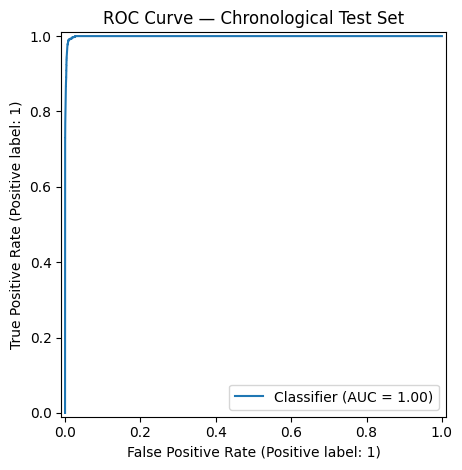

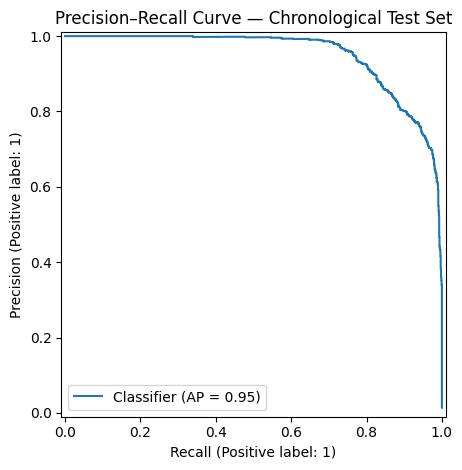

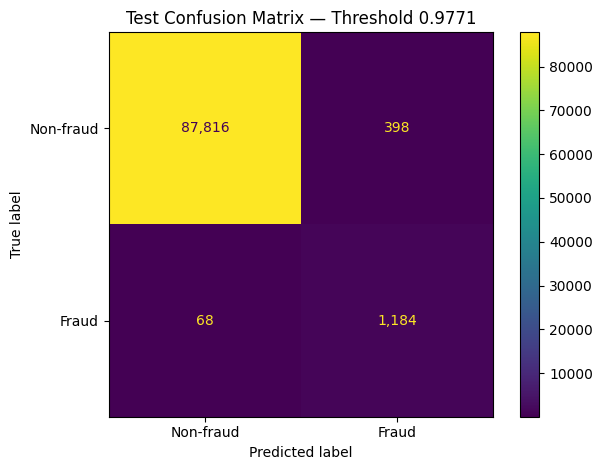

In [8]:
# Cell 9 — Visual evaluation on the test set
# These plots use test predictions only for reporting, not for choosing the threshold.
RocCurveDisplay.from_predictions(y_test, test_probabilities)
plt.title("ROC Curve — Chronological Test Set")
plt.tight_layout()
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, test_probabilities)
plt.title("Precision–Recall Curve — Chronological Test Set")
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions_tuned,
    labels=[0, 1],
    display_labels=["Non-fraud", "Fraud"],
    values_format=","
)
plt.title(f"Test Confusion Matrix — Threshold {threshold:.4f}")
plt.tight_layout()
plt.show()


In [9]:
# Cell 10 — Save the new model and matching metadata WITHOUT overwriting the old model
# The model and metadata are saved together in a new v2 directory.
model_path = OUTPUT_DIR / "xgboost_fraud_model.json"
metadata_path = OUTPUT_DIR / "metadata.json"
metrics_path = OUTPUT_DIR / "evaluation_results.json"

model.save_model(str(model_path))

metadata = {
    "features": FEATURE_NAMES,
    "medians": {feature: float(training_medians[feature]) for feature in FEATURE_NAMES},
    "threshold": float(threshold),
    "threshold_note": threshold_selection_method,
    "categorical_feature": "type",
    "encoding": "One-hot encoding of type into type_* columns; numeric missing values imputed with training-set medians.",
    "excluded_features": [
        "nameOrig",
        "nameDest",
        "newbalanceOrig",
        "newbalanceDest",
        "isFlaggedFraud",
    ],
    "model": {
        "algorithm": "XGBoostClassifier",
        "n_estimators": N_ESTIMATORS,
        "max_depth": 6,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "objective": "binary:logistic",
        "eval_metric": "aucpr",
        "scale_pos_weight": float(scale_pos_weight),
        "random_state": RANDOM_STATE,
        "tree_method": "hist",
    },
    "split": {
        "strategy": "chronological by unique step",
        "train_steps": [int(steps[train_mask].min()), int(steps[train_mask].max())],
        "validation_steps": [int(steps[val_mask].min()), int(steps[val_mask].max())],
        "test_steps": [int(steps[test_mask].min()), int(steps[test_mask].max())],
        "train_rows": int(len(y_train)),
        "validation_rows": int(len(y_val)),
        "test_rows": int(len(y_test)),
        "train_fraud_cases": int(y_train.sum()),
        "validation_fraud_cases": int(y_val.sum()),
        "test_fraud_cases": int(y_test.sum()),
    },
    "validation_threshold_selection": {
        "target_recall": TARGET_RECALL,
        "method": threshold_selection_method,
    },
    "test_metrics_threshold_0_5": test_metrics_050,
    "test_metrics_validation_selected_threshold": test_metrics_tuned,
    "feature_availability_note": (
        "newbalanceOrig and newbalanceDest are excluded because they are post-transaction "
        "values and may leak information unavailable at prediction time."
    ),
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump({
        "threshold_0_5": test_metrics_050,
        "validation_selected_threshold": test_metrics_tuned,
    }, f, indent=2)

zip_path = Path("/content/fraud_deployment_v2.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(model_path, arcname="xgboost_fraud_model.json")
    zf.write(metadata_path, arcname="metadata.json")
    zf.write(metrics_path, arcname="evaluation_results.json")

print("Saved new model:", model_path)
print("Saved matching metadata:", metadata_path)
print("Saved test metrics:", metrics_path)
print("Created package:", zip_path)
print("\nThe previous model files were not overwritten.")


Saved new model: /content/fraud_deployment_v2/xgboost_fraud_model.json
Saved matching metadata: /content/fraud_deployment_v2/metadata.json
Saved test metrics: /content/fraud_deployment_v2/evaluation_results.json
Created package: /content/fraud_deployment_v2.zip

The previous model files were not overwritten.


In [10]:
# Cell 11 — Reload the saved artifact and verify it reproduces the same test probabilities
reloaded_model = xgb.XGBClassifier()
reloaded_model.load_model(str(model_path))

with open(metadata_path, "r", encoding="utf-8") as f:
    reloaded_metadata = json.load(f)

assert reloaded_metadata["features"] == FEATURE_NAMES
assert reloaded_model.get_booster().feature_names == FEATURE_NAMES

# Compare a small sample to verify that the saved model reloads correctly.
sample_size = min(1000, len(X_test))
original_sample = model.predict_proba(X_test.iloc[:sample_size])[:, 1]
reloaded_sample = reloaded_model.predict_proba(X_test.iloc[:sample_size])[:, 1]
max_abs_difference = float(np.max(np.abs(original_sample - reloaded_sample)))

print("Reloaded model feature count:", len(reloaded_metadata["features"]))
print("Metadata threshold:", reloaded_metadata["threshold"])
print("Maximum probability difference on sample:", max_abs_difference)
assert max_abs_difference < 1e-6, "Reloaded model predictions differ from original model."
print("Artifact verification passed.")
print("\nDownload the package from the Colab file browser:")
print(zip_path)


Reloaded model feature count: 9
Metadata threshold: 0.9770604372024536
Maximum probability difference on sample: 0.0
Artifact verification passed.

Download the package from the Colab file browser:
/content/fraud_deployment_v2.zip
